# 01 — Data Analysis: Pre-bedtime Device Use and Sleep Among University Students

**Authors:** Karabai Eldos, Serikova Zhanel  
**Design:** secondary analysis of an open cross-sectional student survey (N = 300).  
**Data:** Nawaz, S. (2026). *Academic Stress, Sleep Quality, and Lifestyle Factors Among University Students.* Mendeley Data, v1, DOI [10.17632/srd3wmjd4r.1](https://doi.org/10.17632/srd3wmjd4r.1), licence CC BY 4.0.

**Pipeline:** 1) ingestion & validation (analogue of warm-up filtering) → 2) statistical aggregation → 3) visualization & export.  
Run via *Kernel → Restart & Run All*. All randomness is seeded (`SEED = 42`).

**Research questions (adapted to the variables available in the open dataset):**
- **RQ1** — Is electronic-device use before bed associated with self-rated sleep quality?
- **RQ2** — Do pre-bedtime device use, stress and night-time caffeine predict difficulty falling asleep (proxy for sleep-onset latency)?
- **RQ3** — Which sleep-hygiene factors (sleep duration ≥ 7 h, bedtime after midnight, device use) are associated with good sleep quality, adjusting for stress, caffeine, gender, age?

## 0. Setup & reproducibility
Reusable logic lives in `src/process_data.py` and `src/visualize.py`; the notebook calls it and shows every intermediate result.

In [1]:
import os, sys, platform
from pathlib import Path

ROOT = Path.cwd().parent if Path.cwd().name == "notebooks" else Path.cwd()
os.chdir(ROOT)
sys.path.insert(0, str(ROOT))

import numpy as np
import pandas as pd
import scipy, statsmodels, matplotlib
from IPython.display import Image, display

from src import process_data as pdta
from src import visualize as viz

SEED = 42
np.random.seed(SEED)   # global seed; bootstrap/jitter use their own seeded Generators

pd.set_option("display.width", 170); pd.set_option("display.max_columns", 30)
print("Python     :", platform.python_version())
print("numpy      :", np.__version__, "| pandas:", pd.__version__)
print("scipy      :", scipy.__version__, "| statsmodels:", statsmodels.__version__)
print("matplotlib :", matplotlib.__version__)
print("Seed       :", SEED, "| bootstrap resamples:", pdta.N_BOOT)

Python     : 3.12.3
numpy      : 2.5.4 | pandas: 3.0.6
scipy      : 1.18.1 | statsmodels: 0.15.0
matplotlib : 3.11.2
Seed       : 42 | bootstrap resamples: 2000


## 1. Data ingestion & validation (analogue of warm-up filtering)
The raw file is converted from the original CSV (`src/convert_raw.py`). Before any statistic is computed the data pass a validation cascade: label harmonisation (recoded cells are counted), then exclusion of duplicates, unknown category labels and out-of-range values. The **exclusion rate** is tracked as the guardrail metric.

In [2]:
raw = pdta.load_raw("data/raw/test_run.jsonl")
print("Raw records:", len(raw), "| variables:", raw.shape[1])
raw.head()

Raw records: 300 | variables: 31


,Q Number,Age,Gender,Type_of_residence,Current_CGPA,Financial_stress_level,Discipline_Program,Current_Study_Year,Current_stress_level,Depression_level,Anxiety_level,Overwhelmed_by_academic_workload,Used_counseling_services,Family_history_of_health_issues,Strength_of_social_support,...,Average_sleep_duration_per_night,Bedtime_on_regular_nights,Sleep_quality,Difficulty_falling_asleep,Use_of_electronic_devices_before_bed,Night_time_caffeine_consumption,Daytime_sleepiness_during_classes,Hours_spent_daily_on_academic_activities,Physical_activity_per_week,Diet_quality,Smoking_or_substance_use,Chronic_illness,Awareness_of_recommended_sleep,Skipped_class_due_to_poor_sleep_or_stress,Impact_of_stress_on_academic_performance
0,1,19,Female,On-Campus,3.85,1,NFE,3,5,1,4,Never,Occasionally,Yes,High,...,5-6 hrs,After 12 AM,Good,Rarely,Yes,Yes,Rarely,>4 hrs,Moderate,Average,Occasionally,No,Yes,No,Somewhat Positive
1,2,18,Male,Off-Campus,3.96,4,CIVIL,3,1,1,1,Rarely,Frequently,Yes,Moderate,...,<5 hrs,After 12 AM,Average,Almost Always,Yes,Yes,Often,1-2 hrs,Low,Good,Occasionally,No,No,No,Somewhat Positive
2,3,28,Male,Off-Campus,3.23,1,NFE,2,5,1,3,Often,Never,No,High,...,7-8 hrs,After 12 AM,Poor,Sometimes,No,No,Never,3-4 hrs,Low,Average,Never,No,No,Yes,No Impact
3,4,19,Female,With Family,4.00,1,NFE,3,5,2,1,Sometimes,Never,No,Moderate,...,5-6 hrs,After 12 AM,Poor,Almost Always,Yes,No,Rarely,3-4 hrs,High,Poor,Never,No,Yes,Yes,Very Positive
4,5,21,Female,Off-Campus,3.42,3,CSE,4,3,5,1,Never,Occasionally,No,High,...,5-6 hrs,After 12 AM,Average,Almost Always,Yes,Yes,Rarely,<1 hrs,Moderate,Good,Occasionally,No,Yes,Yes,Somewhat Negative


In [3]:
valid, log = pdta.validate(raw)
d = pdta.derive(valid)
print(log.to_string(index=False))
print()
print(f"Raw records               : {log.attrs['n_raw']}")
print(f"Analysed sample           : {len(d)}")
print(f"Guardrail - exclusion rate: {pdta.exclusion_rate(log):.1%}")
print(f"Share of recoded cells    : {log.attrs['recode_rate']:.2%}")

                                          step  affected
recoded label cells (whitespace / Yes-No case)         0
                         duplicate respondents         0
                        unknown category label         0
                    numeric value out of range         0

Raw records               : 300
Analysed sample           : 300
Guardrail - exclusion rate: 0.0%
Share of recoded cells    : 0.00%


In [4]:
# Sample description
print(f"Age: mean {d.age.mean():.1f} ± {d.age.std():.1f}, median {d.age.median():.0f} (range {d.age.min():.0f}-{d.age.max():.0f})")
print(f"Female: {100*(d.male==0).mean():.1f} %   CGPA: mean {d.Current_CGPA.mean():.2f} ± {d.Current_CGPA.std():.2f}")
for col in ["Use_of_electronic_devices_before_bed", "Sleep_quality", "Difficulty_falling_asleep",
            "Average_sleep_duration_per_night", "Bedtime_on_regular_nights", "Night_time_caffeine_consumption"]:
    vc = d[col].value_counts()
    print(f"\n{col}")
    print((pd.DataFrame({"n": vc, "%": (100*vc/len(d)).round(1)})).to_string())

Age: mean 21.9 ± 3.1, median 21 (range 18-35)
Female: 51.7 %   CGPA: mean 3.46 ± 0.29

Use_of_electronic_devices_before_bed
                                        n     %
Use_of_electronic_devices_before_bed           
Yes                                   277  92.3
No                                     23   7.7

Sleep_quality
                 n     %
Sleep_quality           
Good           159  53.0
Average        115  38.3
Poor            26   8.7

Difficulty_falling_asleep
                            n     %
Difficulty_falling_asleep          
Sometimes                  95  31.7
Rarely                     71  23.7
Never                      55  18.3
Almost Always              49  16.3
Often                      30  10.0

Average_sleep_duration_per_night
                                    n     %
Average_sleep_duration_per_night           
5-6 hrs                           159  53.0
7-8 hrs                            88  29.3
<5 hrs                             40  13.3
>8 hrs     

> **Important data limitation.** Only a small number of students report *no* device use before bed (see above). Comparisons between device users and non-users therefore have **low statistical power**; wide confidence intervals are expected and must be interpreted with care.

## 2. Statistical aggregation
### 2.1 Descriptive statistics
For each numeric variable and self-rated sleep-quality group: mean ± SD, median, p25/p75, **p95, p99** and the **95 % bootstrap CI of the median** (2000 resamples, seeded). `difficulty_score` codes *Never = 0 … Almost always = 4*.

In [5]:
summary = pdta.describe(d, by="Sleep_quality", seed=SEED)
summary.round(2)

,grouping,group,variable,n,mean,sd,median,p25,p75,p95,p99,median_ci_low,median_ci_high
0,Sleep_quality,ALL,Current_stress_level,300,2.55,1.42,2.00,1.00,4.00,5.00,5.0,2.00,3.00
1,Sleep_quality,Poor,Current_stress_level,26,2.65,1.60,2.00,1.00,4.00,5.00,5.0,1.00,3.50
2,Sleep_quality,Average,Current_stress_level,115,2.86,1.44,3.00,1.00,4.00,5.00,5.0,3.00,3.00
3,Sleep_quality,Good,Current_stress_level,159,2.30,1.34,2.00,1.00,3.00,5.00,5.0,2.00,2.00
4,Sleep_quality,ALL,Anxiety_level,300,2.53,1.39,2.00,1.00,4.00,5.00,5.0,2.00,3.00
5,Sleep_quality,Poor,Anxiety_level,26,2.96,1.54,3.00,1.25,4.00,5.00,5.0,2.00,4.00
6,Sleep_quality,Average,Anxiety_level,115,2.68,1.43,3.00,1.00,4.00,5.00,5.0,2.00,3.00
7,Sleep_quality,Good,Anxiety_level,159,2.36,1.32,2.00,1.00,3.00,5.00,5.0,2.00,3.00
8,Sleep_quality,ALL,Depression_level,300,2.34,1.37,2.00,1.00,3.00,5.00,5.0,2.00,2.00
9,Sleep_quality,Poor,Depression_level,26,2.35,1.35,2.00,1.00,3.00,4.75,5.0,1.00,3.00


### 2.2 RQ1 — device use before bed vs. sleep quality
Share of good sleepers per group (Wilson 95 % CI), risk difference (bootstrap CI), Fisher's exact odds ratio and Mann–Whitney test on the 3-level ordinal quality (rank-biserial effect size). Expected direction: device users sleep worse (negative differences).

In [6]:
display(pdta.share_by_device(d).assign(rate=lambda x: (x.rate*100).round(1),
                                      ci_low=lambda x: (x.ci_low*100).round(1),
                                      ci_high=lambda x: (x.ci_high*100).round(1)))
t1 = pdta.rq1(d, seed=SEED)
t1.drop(columns=["model", "term"]).round(4)

,group,n,good_n,rate,ci_low,ci_high
0,No device use,23,12,52.2,33.0,70.8
1,Device use,277,147,53.1,47.2,58.9


,rq,test,estimate,ci_low,ci_high,p_value,n,h1_met
0,RQ1,"Risk difference, good sleep: device users - no...",0.0089,-0.2011,0.2298,1.0000,300,False
1,RQ1,"Odds ratio of good sleep, users vs non-users (...",1.0365,0.4424,2.4287,1.0000,300,False
2,RQ1,"Rank-biserial r, sleep-quality rank, users vs ...",0.0083,-0.2052,0.2486,0.9418,300,False


### 2.3 RQ2 — predictors of difficulty falling asleep
Proportional-odds (ordered logit) model, outcome: *Never < Rarely < Sometimes < Often < Almost always*; predictors: device use, stress (1–5), night-time caffeine, gender, age. OR > 1 = more difficulty falling asleep. A Spearman correlation (bootstrap CI) of stress vs. difficulty complements the model.

In [7]:
t2 = pdta.rq2(d, seed=SEED)
t2.drop(columns=["model", "term"]).round(4)

,rq,test,estimate,ci_low,ci_high,p_value,n,h1_met
0,RQ2,"Ordered-logit OR, difficulty falling asleep: p...",0.8257,0.3907,1.7451,0.6160,300,False
1,RQ2,"Ordered-logit OR, difficulty falling asleep: s...",0.9172,0.7943,1.0590,0.2387,300,False
2,RQ2,"Ordered-logit OR, difficulty falling asleep: n...",0.8670,0.5325,1.4117,0.5661,300,False
3,RQ2,"Ordered-logit OR, difficulty falling asleep: m...",1.2309,0.8189,1.8502,0.3177,300,None
4,RQ2,"Ordered-logit OR, difficulty falling asleep: a...",0.9894,0.9270,1.0560,0.7479,300,None
5,RQ2,Spearman rho: stress level vs difficulty falli...,-0.0660,-0.1752,0.0448,0.2548,300,False


### 2.4 RQ3 — factors associated with good sleep quality
Logistic regression (outcome: sleep quality rated *Good* vs. *Average/Poor*). OR > 1 = higher odds of good sleep. Expected directions: ≥ 7 h sleep ↑; late bedtime, device use, stress, caffeine ↓.

In [8]:
t3 = pdta.rq3(d)
t3.drop(columns=["model", "term"]).round(4)

,rq,test,estimate,ci_low,ci_high,p_value,n,h1_met
0,RQ3,"Logistic OR, good sleep quality: sleep duratio...",0.6153,0.3743,1.0112,0.0554,300,False
1,RQ3,"Logistic OR, good sleep quality: bedtime after...",1.1454,0.5834,2.2491,0.6933,300,False
2,RQ3,"Logistic OR, good sleep quality: pre-bedtime d...",0.9420,0.3875,2.2901,0.8952,300,False
3,RQ3,"Logistic OR, good sleep quality: stress level ...",0.7575,0.6402,0.8964,0.0012,300,True
4,RQ3,"Logistic OR, good sleep quality: night-time ca...",0.8606,0.4949,1.4964,0.5947,300,False
5,RQ3,"Logistic OR, good sleep quality: male vs female",0.9883,0.6192,1.5774,0.9606,300,None
6,RQ3,"Logistic OR, good sleep quality: age (+1 year)",0.9756,0.9044,1.0524,0.5228,300,None


### 2.5 Persist aggregated tables
Small, git-friendly CSVs used by the README and figures.

In [9]:
tests = pd.concat([t1, t2, t3], ignore_index=True)
Path("data/processed").mkdir(parents=True, exist_ok=True)
summary.round(4).to_csv("data/processed/metrics_summary.csv", index=False)
tests.round(6).to_csv("data/processed/tests_summary.csv", index=False)
for f in sorted(Path("data/processed").glob("*.csv")):
    print(f"{f.name:25s} {f.stat().st_size} bytes")
print()
print("Pre-specified hypotheses (H1 met = p < 0.05 AND expected direction):")
tests.loc[tests.h1_met.notna(), ["rq", "test", "estimate", "p_value", "h1_met"]].round(4)

metrics_summary.csv       1758 bytes
tests_summary.csv         2279 bytes

Pre-specified hypotheses (H1 met = p < 0.05 AND expected direction):


,rq,test,estimate,p_value,h1_met
0,RQ1,"Risk difference, good sleep: device users - no...",0.0089,1.0000,False
1,RQ1,"Odds ratio of good sleep, users vs non-users (...",1.0365,1.0000,False
2,RQ1,"Rank-biserial r, sleep-quality rank, users vs ...",0.0083,0.9418,False
3,RQ2,"Ordered-logit OR, difficulty falling asleep: p...",0.8257,0.6160,False
4,RQ2,"Ordered-logit OR, difficulty falling asleep: s...",0.9172,0.2387,False
5,RQ2,"Ordered-logit OR, difficulty falling asleep: n...",0.8670,0.5661,False
8,RQ2,Spearman rho: stress level vs difficulty falli...,-0.0660,0.2548,False
9,RQ3,"Logistic OR, good sleep quality: sleep duratio...",0.6153,0.0554,False
10,RQ3,"Logistic OR, good sleep quality: bedtime after...",1.1454,0.6933,False
11,RQ3,"Logistic OR, good sleep quality: pre-bedtime d...",0.9420,0.8952,False


## 3. Visualization & export
All figures follow the rules of scientific visualization: **(1)** labelled axes with units / scales (odds ratios on a log scale); **(2)** uncertainty shown (Wilson CI bands/bars, 95 % CI of odds ratios); **(3)** colour-blind-safe palette plus distinct markers / linestyles / hatches. Each figure is exported as vector **PDF** and **PNG at 300 DPI**.

In [10]:
viz.make_all(d, tests)
for f in sorted(Path("reports/figures").glob("*")):
    print(f"{f.name:40s} {f.stat().st_size/1024:8.1f} KB")

fig1_latency_vs_load.pdf                     19.7 KB
fig1_latency_vs_load.png                    213.3 KB
fig2_distribution_boxplot.pdf                34.6 KB
fig2_distribution_boxplot.png               222.5 KB
fig3_device_use_vs_sleep_quality.pdf         30.6 KB
fig3_device_use_vs_sleep_quality.png        140.6 KB
fig4_odds_ratios_forest.pdf                  21.5 KB
fig4_odds_ratios_forest.png                 246.5 KB


### Figure 1 — Frequent difficulty falling asleep vs. stress level, by night-time caffeine (95 % Wilson CI)

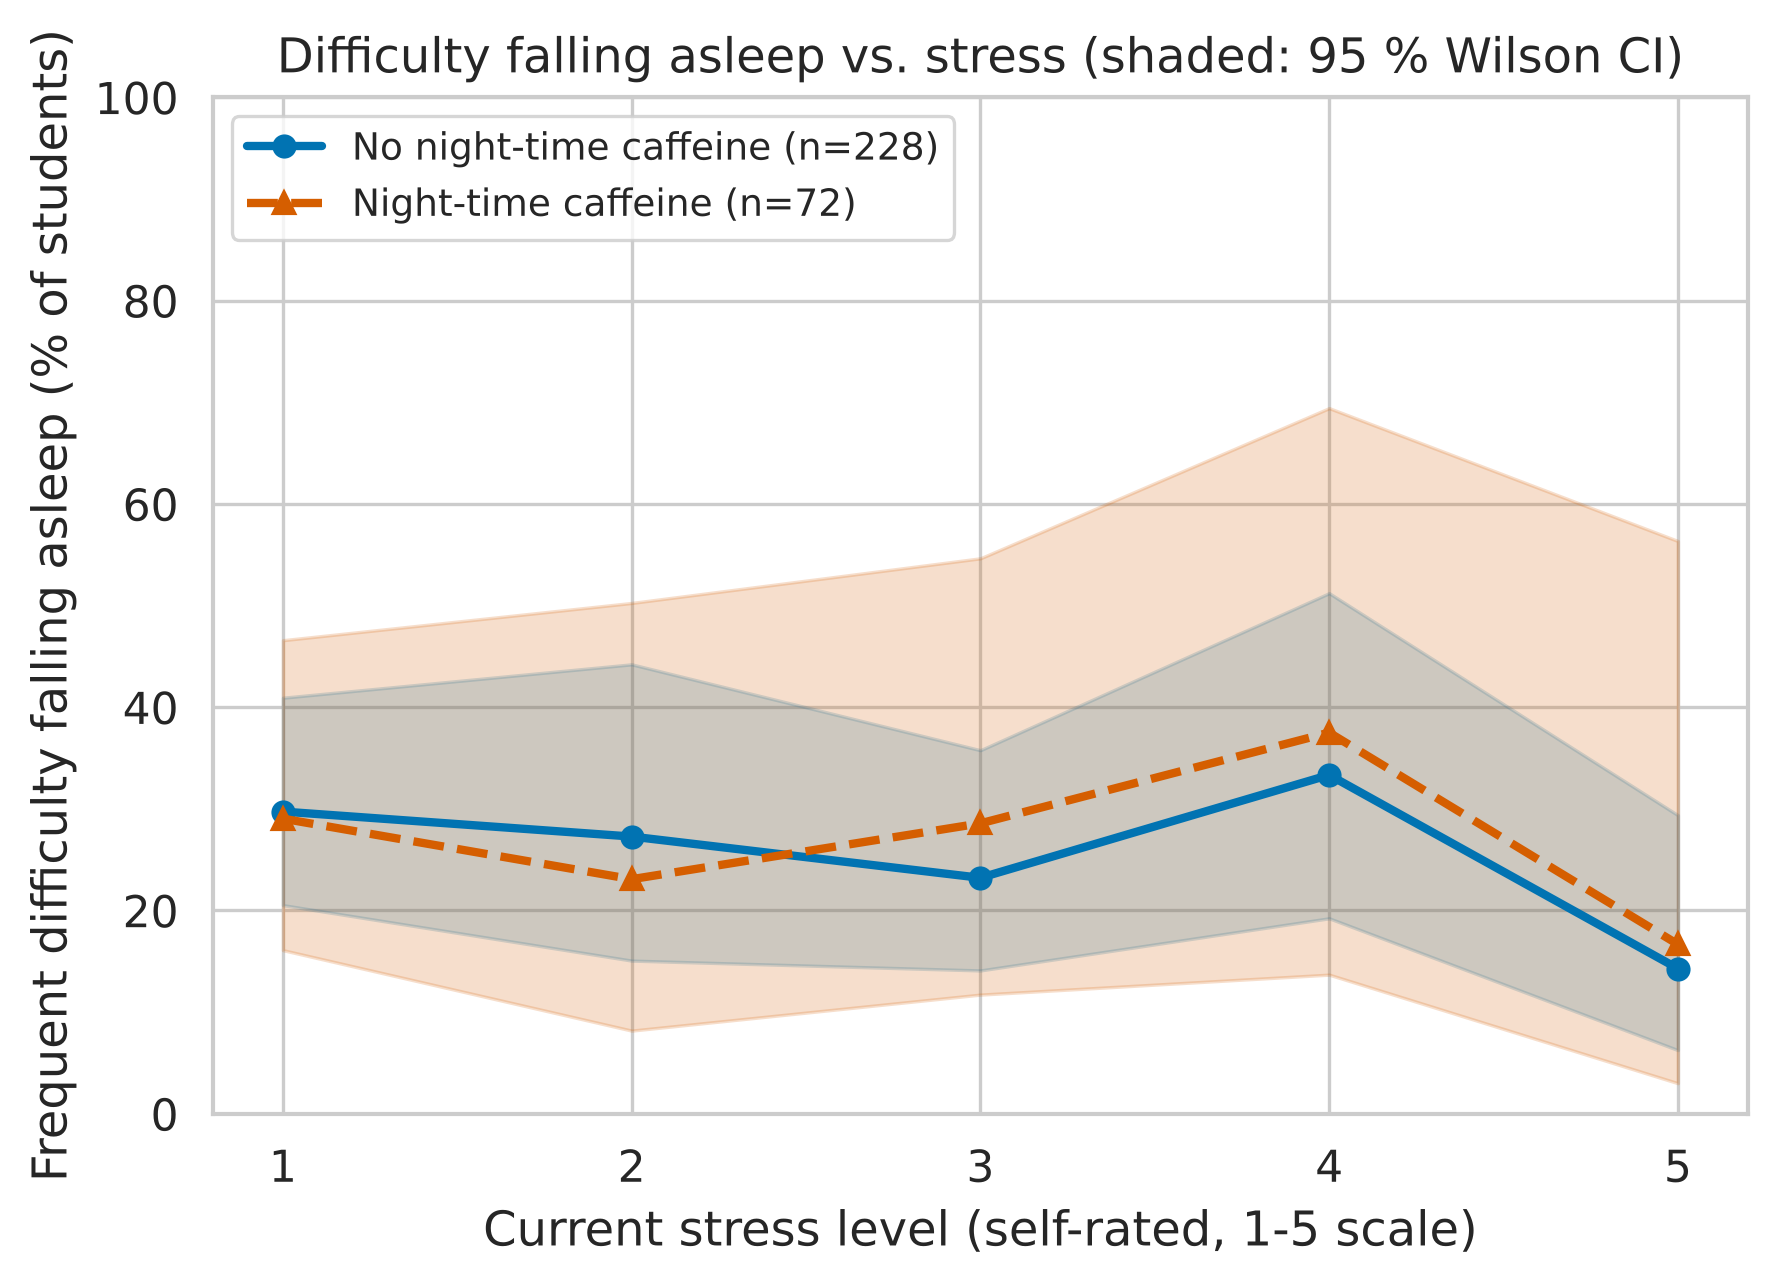

In [11]:
display(Image("reports/figures/fig1_latency_vs_load.png", width=620))

### Figure 2 — Stress level by self-rated sleep quality

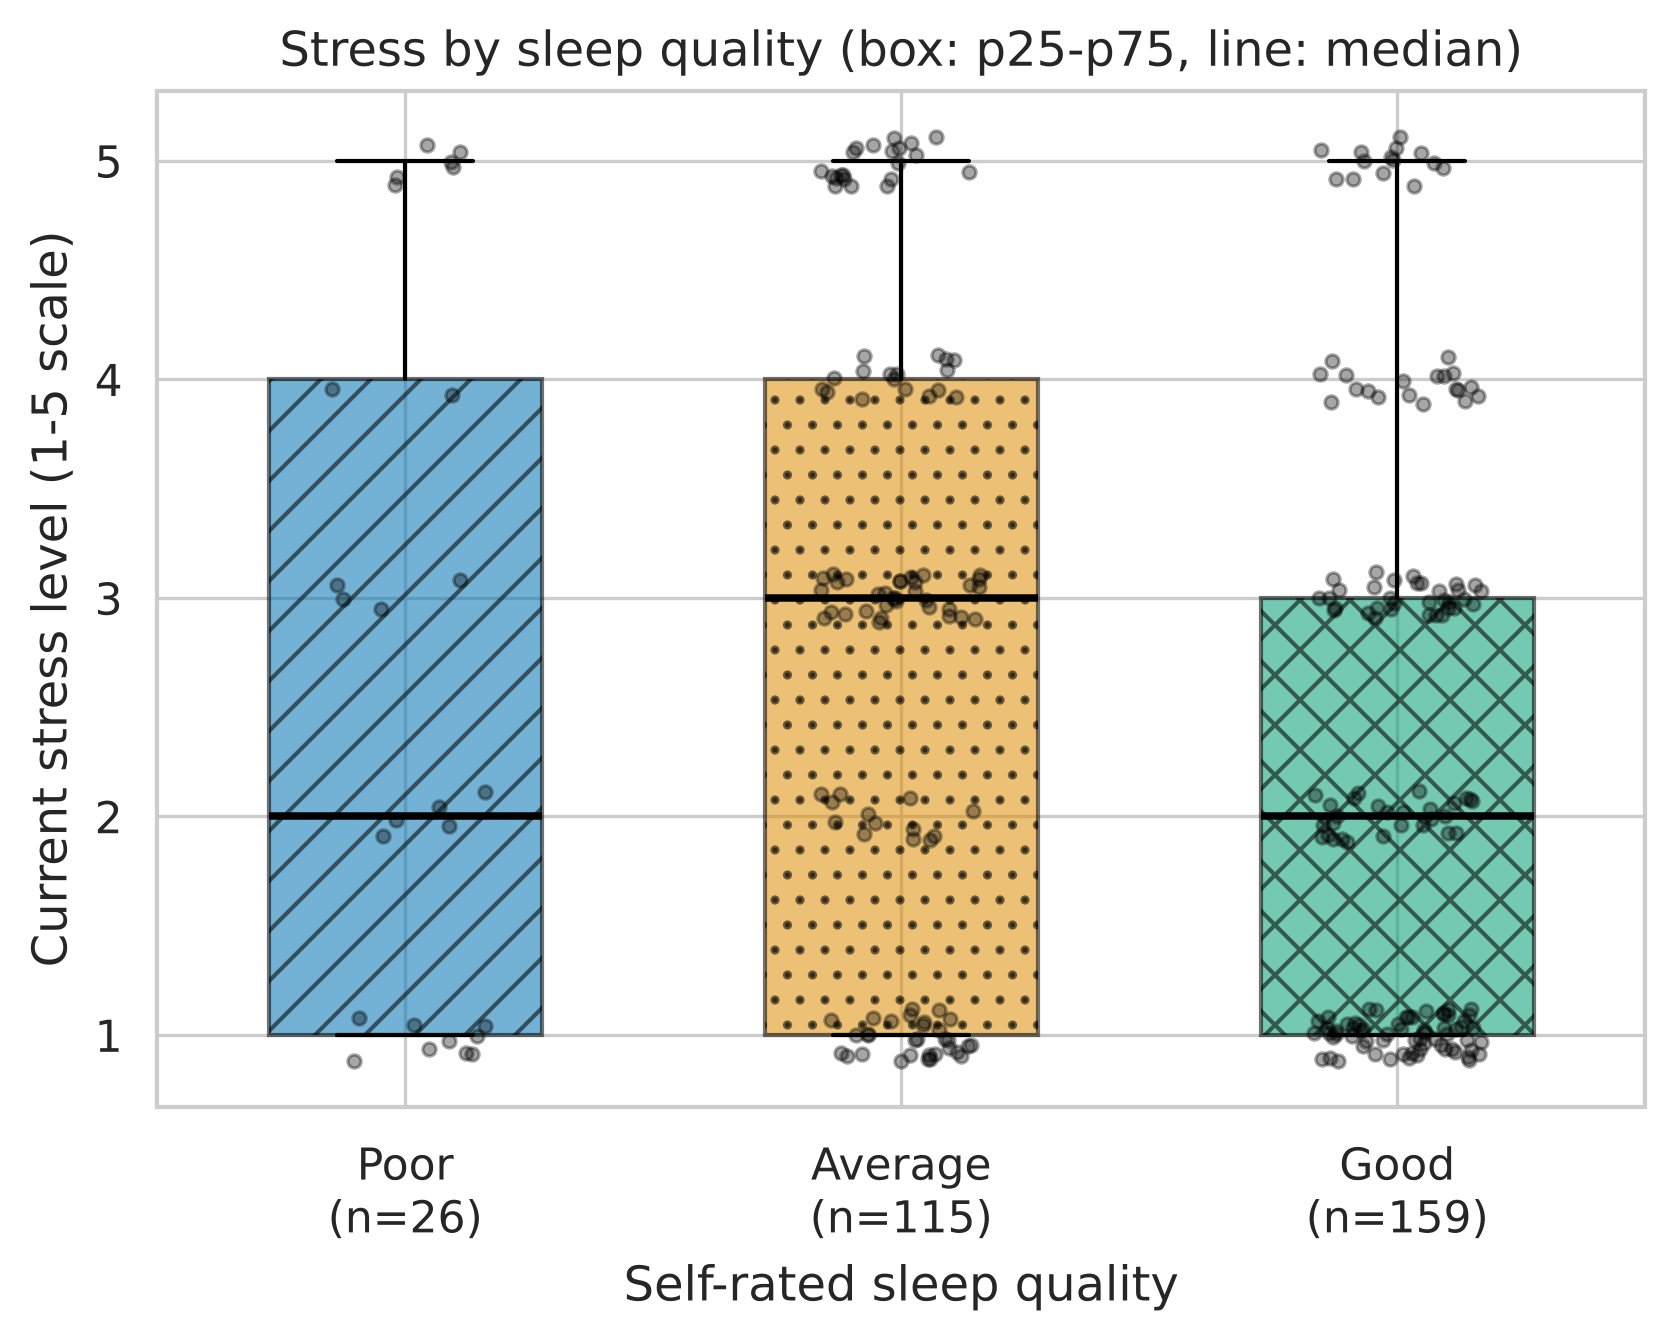

In [12]:
display(Image("reports/figures/fig2_distribution_boxplot.png", width=620))

### Figure 3 — RQ1: good sleep quality by pre-bedtime device use

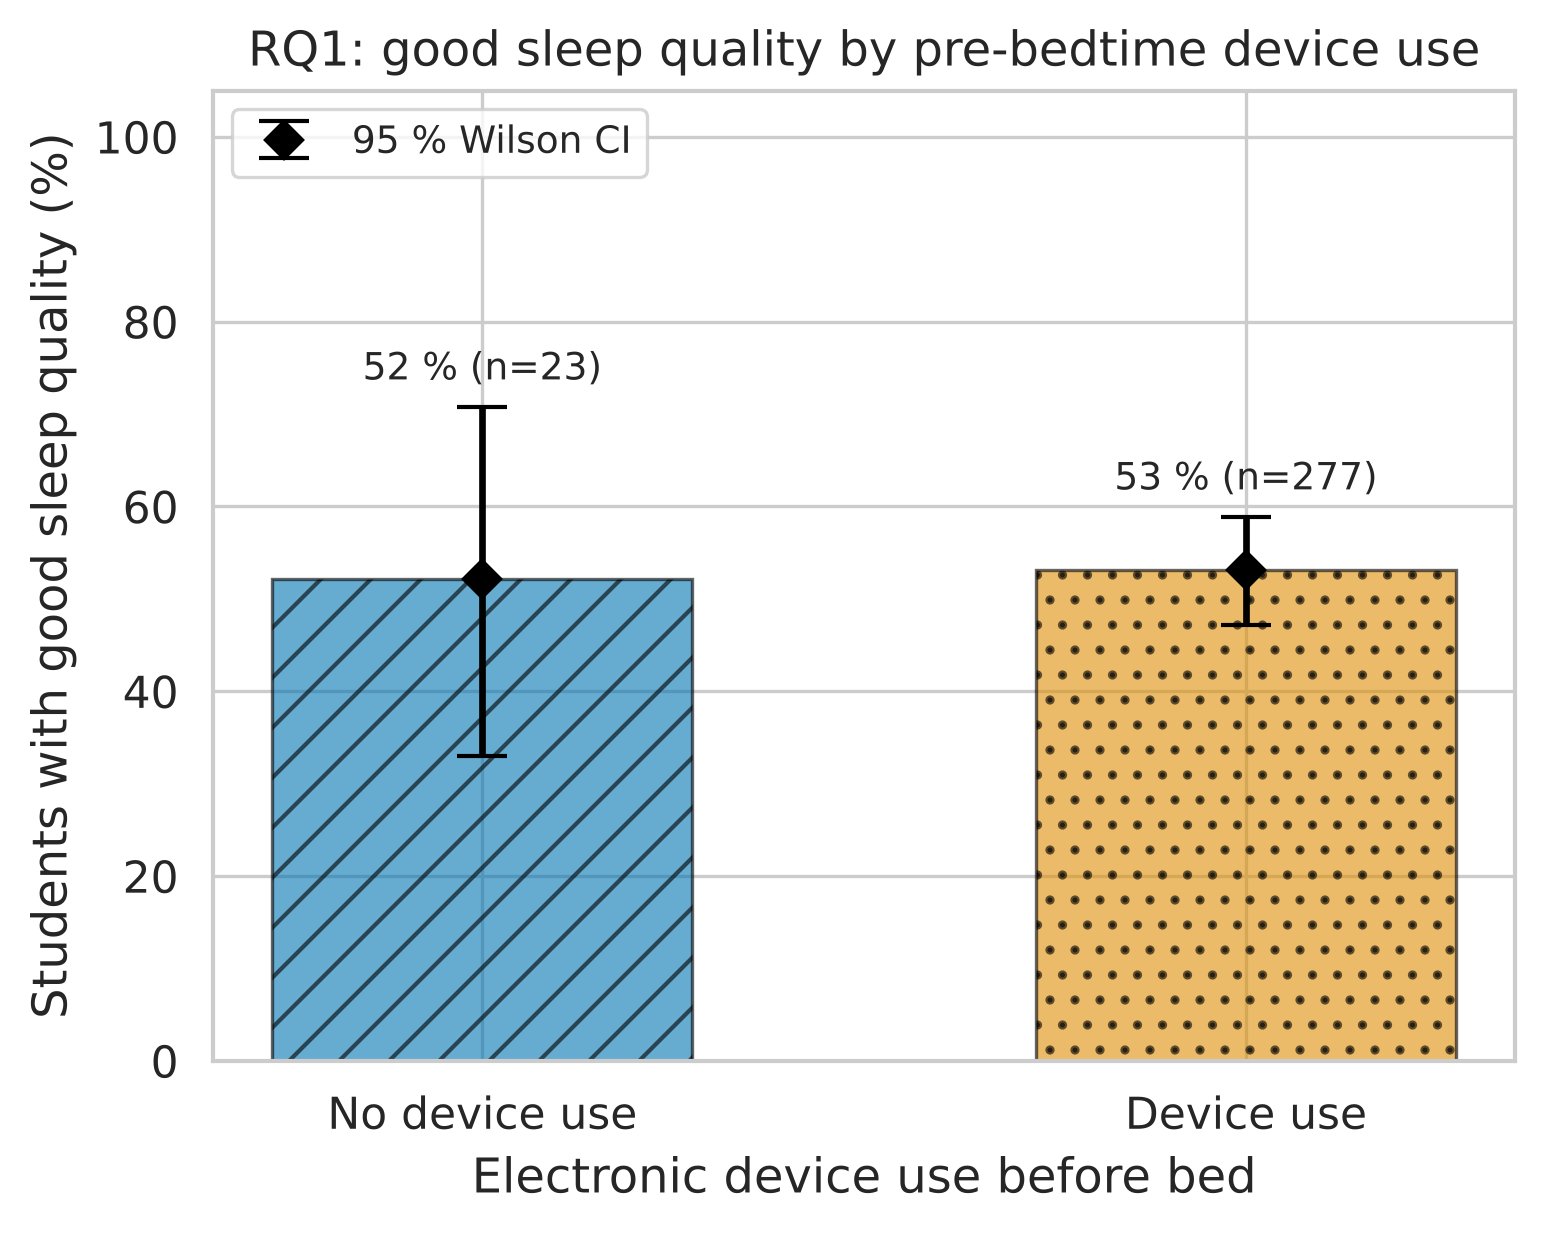

In [13]:
display(Image("reports/figures/fig3_device_use_vs_sleep_quality.png", width=520))

### Figure 4 — RQ2 / RQ3: adjusted odds ratios with 95 % CI

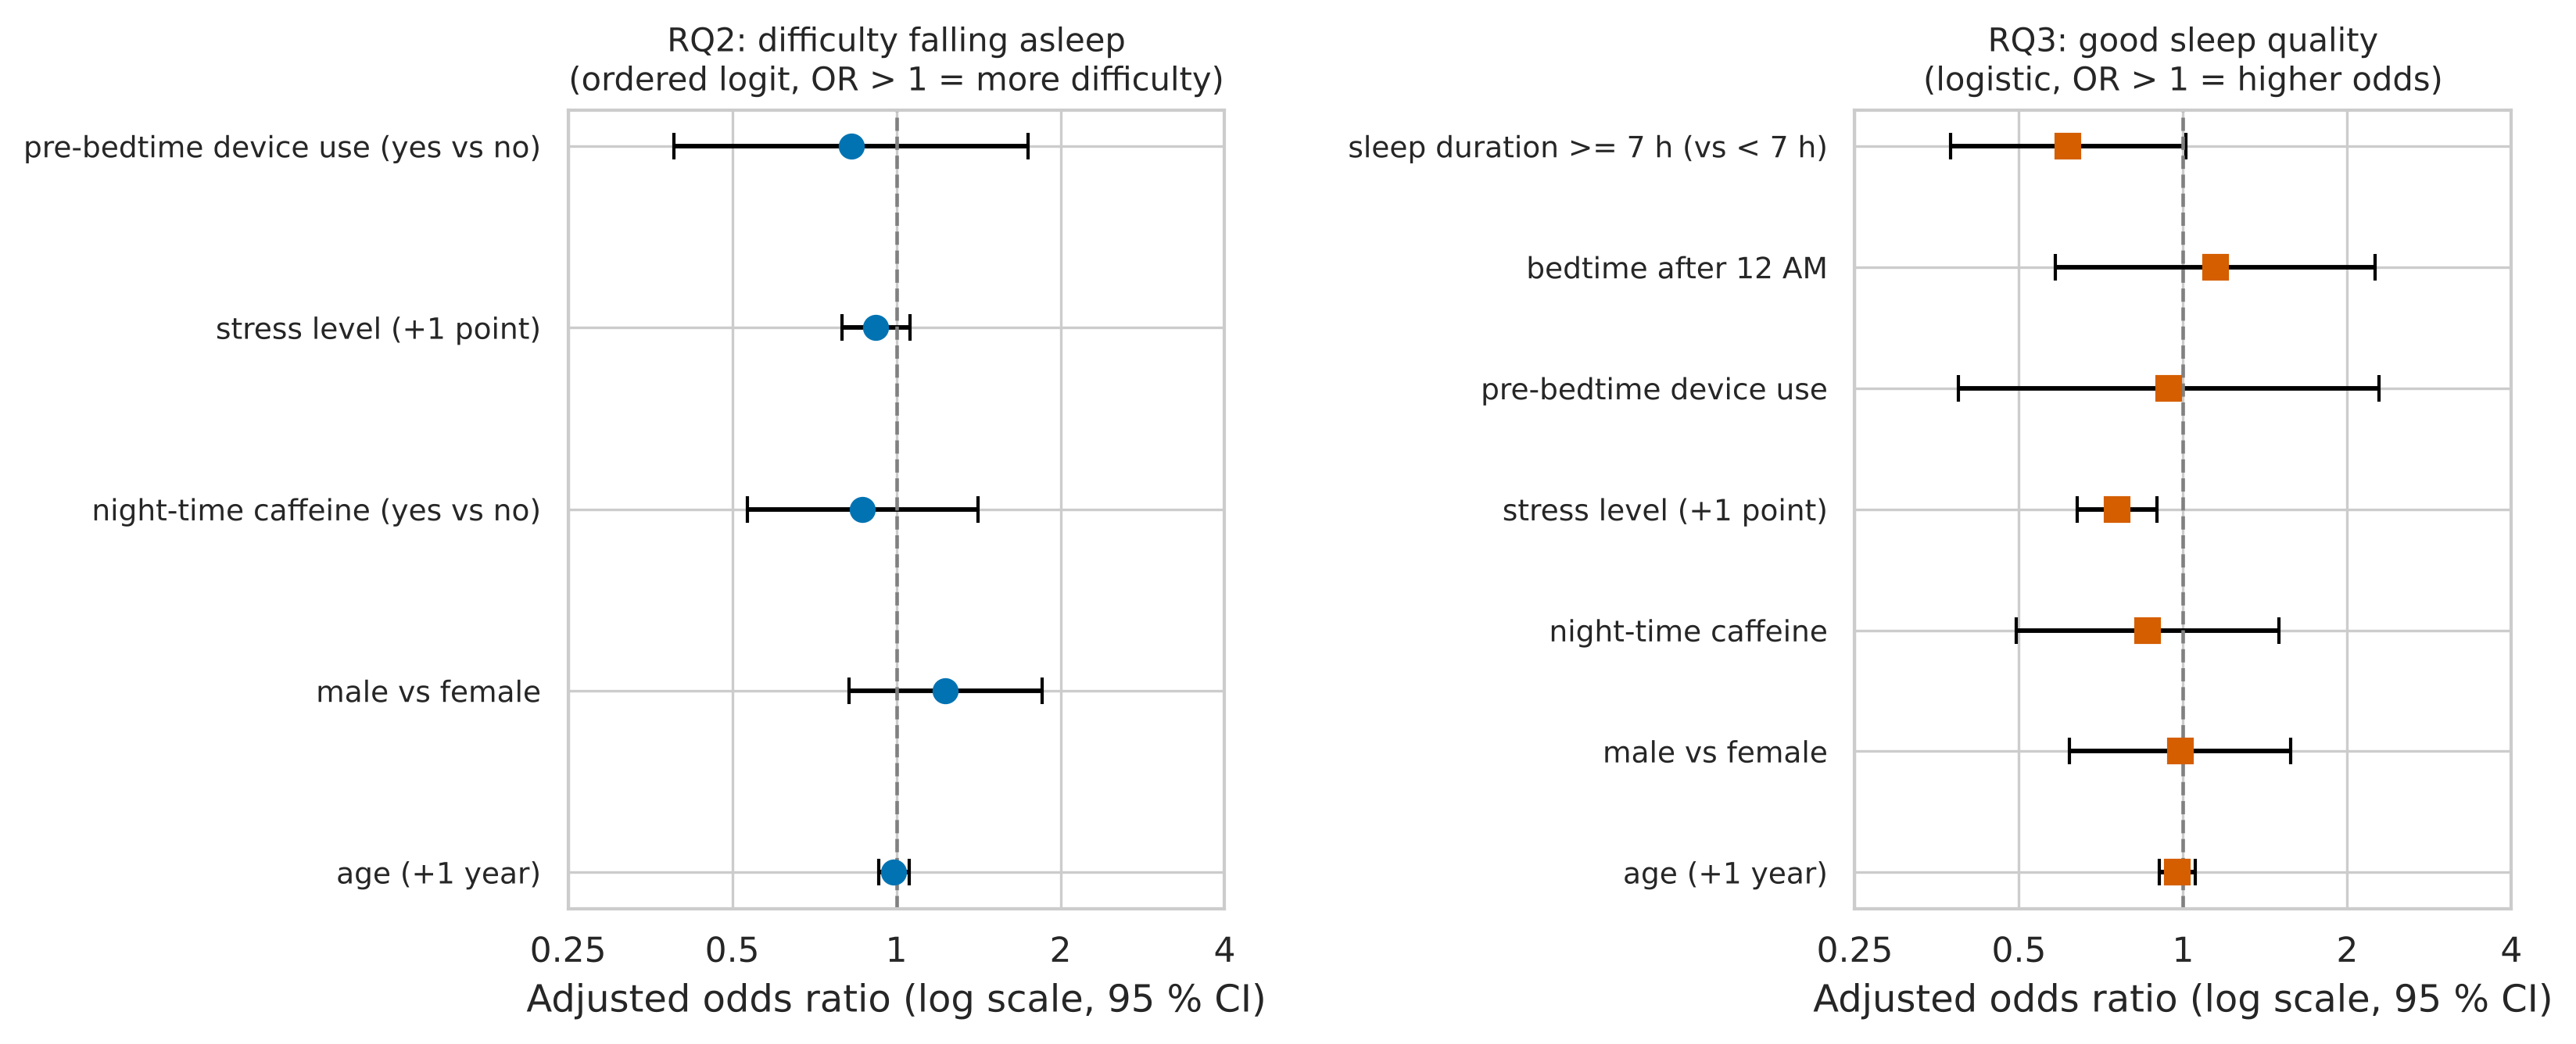

In [14]:
display(Image("reports/figures/fig4_odds_ratios_forest.png", width=900))

## 4. Interpretation
- **RQ1:** the share of good sleepers is practically identical in device users and non-users; the 95 % CIs of the risk difference and odds ratio are wide and include 0 / 1 → **no evidence of an association**, but with only a few non-users the study cannot exclude a moderate effect (low power).
- **RQ2:** neither device use, caffeine nor stress is associated with difficulty falling asleep; all CIs include 1.
- **RQ3:** higher stress is associated with lower odds of good sleep quality (adjusted OR per stress point ≈ 0.76, 95 % CI excludes 1). Sleep duration ≥ 7 h shows an *unexpected* borderline association in the opposite direction; this should be read as a possible artefact of coarse categories and self-rated quality, not as a real effect.
- **Multiple testing:** the analyses are exploratory; no correction was applied.

**Limitations.** Cross-sectional design (association, not causation); self-reported measures; no PSQI, no screen-time hours, no sleep-onset latency in minutes (proxies used); very unbalanced exposure (device use: ~92 %); convenience sample from one institution; secondary data.